In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost torch joblib shap

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)

from sklearn.feature_selection import (
    mutual_info_classif,
    SelectKBest
)

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    log_loss
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.svm import SVC

from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import joblib

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.5.1
Selected device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [5]:
DATA_PATH = "Crop_recommendation.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
print("Dataset Information")
print("=" * 50)

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Information

Shape:
(2200, 8)

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data Types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [7]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [8]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:",
      missing_values.sum())

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total Missing Values: 0


In [9]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after duplicate removal:",
      df.shape)

Duplicate Records: 0
Dataset shape after duplicate removal: (2200, 8)


In [10]:
X = df.drop("label", axis=1)

y = df["label"]

print("Input Features:")
print(X.columns.tolist())

print("\nNumber of Input Features:", X.shape[1])

print("\nTarget Classes:", y.nunique())

Input Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Number of Input Features: 7

Target Classes: 22


In [11]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

num_classes = len(class_names)

print("Encoded Classes:")
print(class_names)

print("\nNumber of Classes:", num_classes)

Encoded Classes:
['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']

Number of Classes: 22


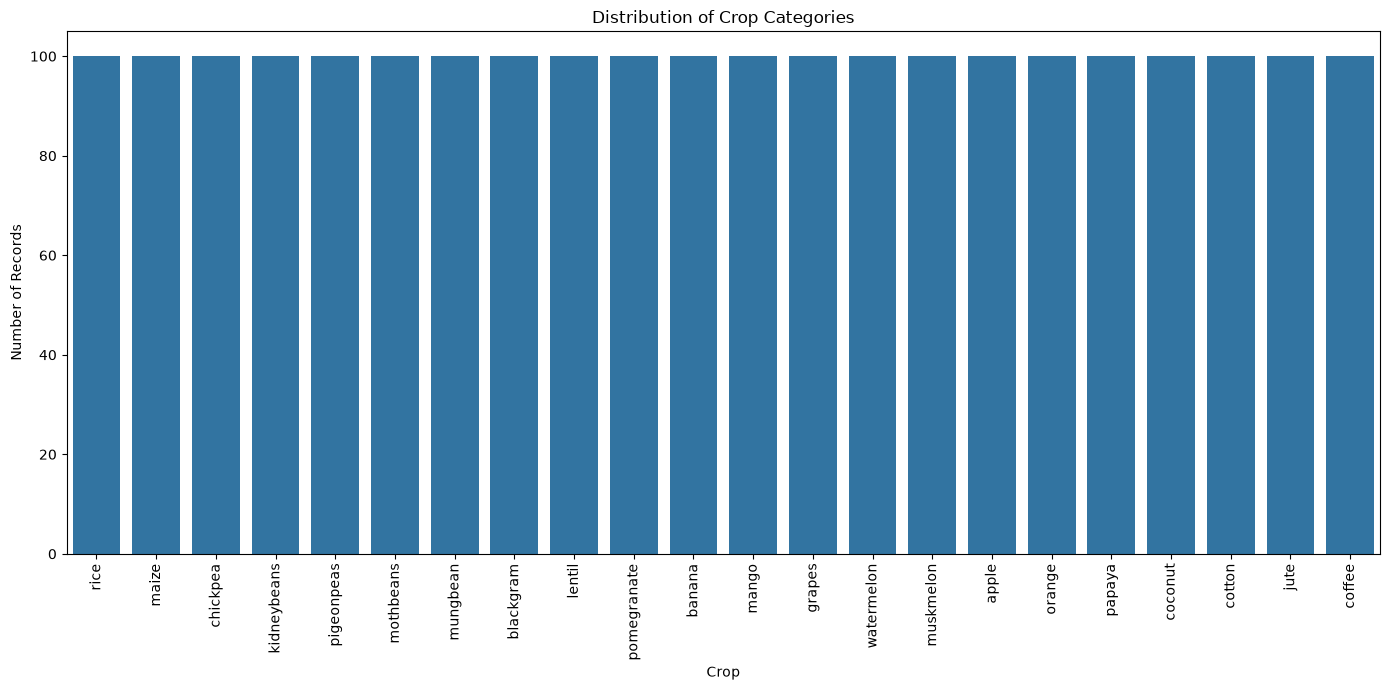

In [12]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("Distribution of Crop Categories")
plt.xlabel("Crop")
plt.ylabel("Number of Records")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

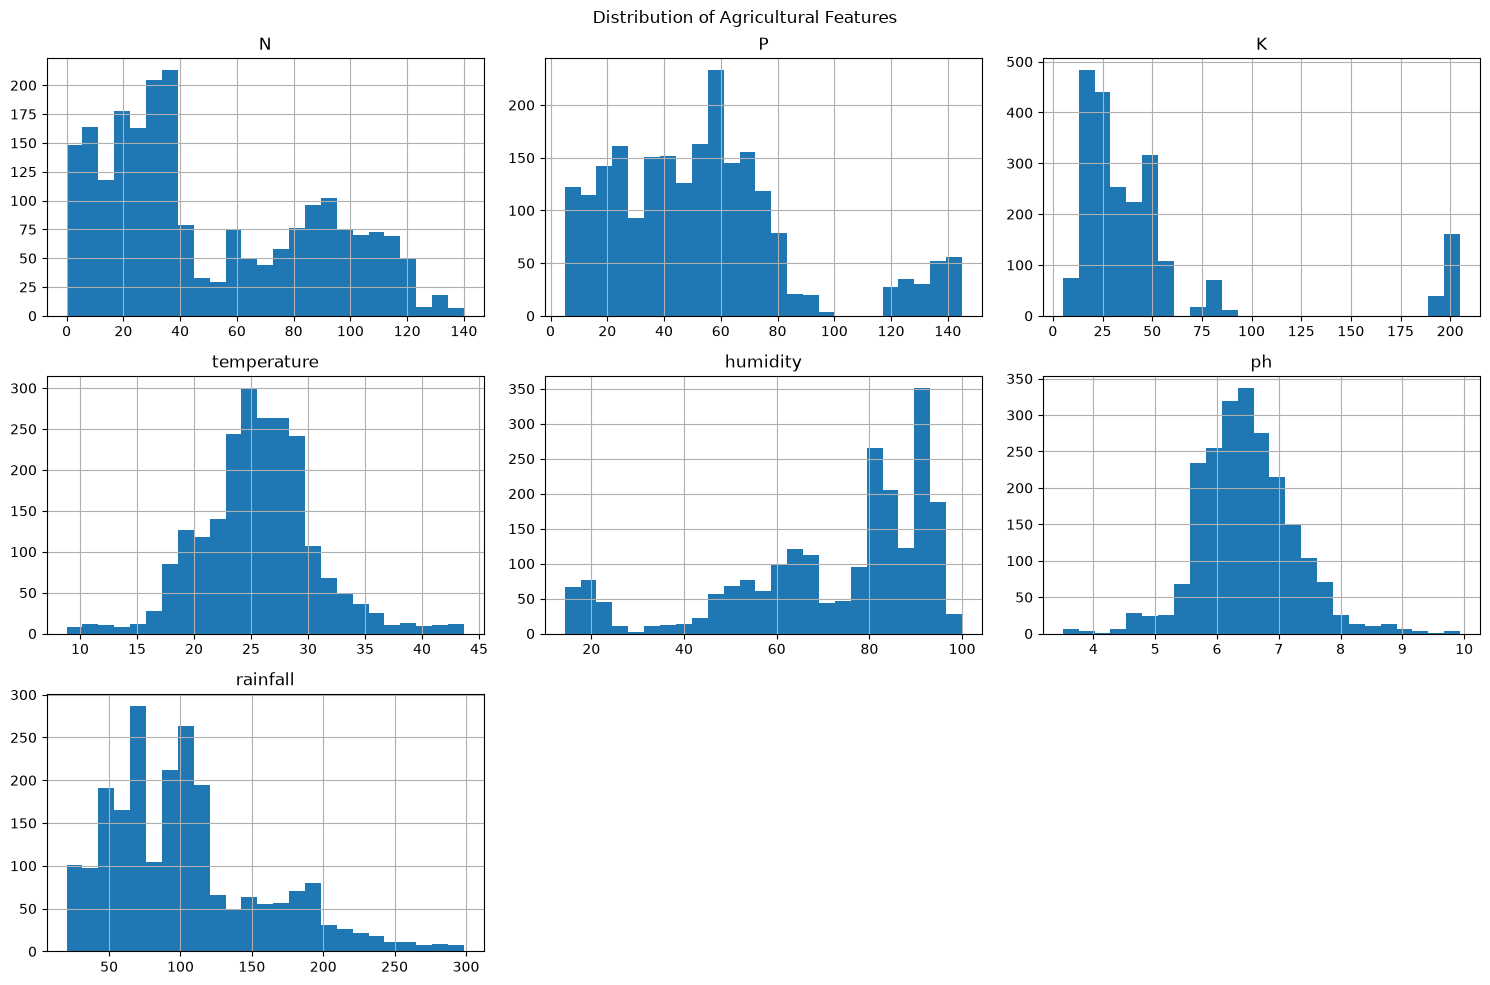

In [13]:
features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

df[features].hist(
    figsize=(15, 10),
    bins=25
)

plt.suptitle("Distribution of Agricultural Features")

plt.tight_layout()
plt.show()

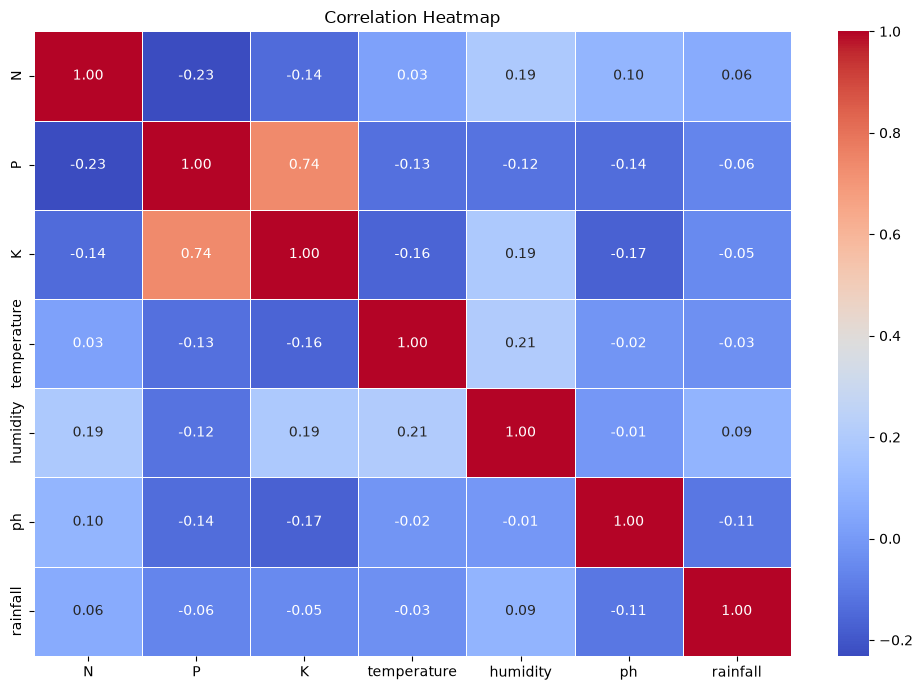

In [14]:
plt.figure(figsize=(10, 7))

correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

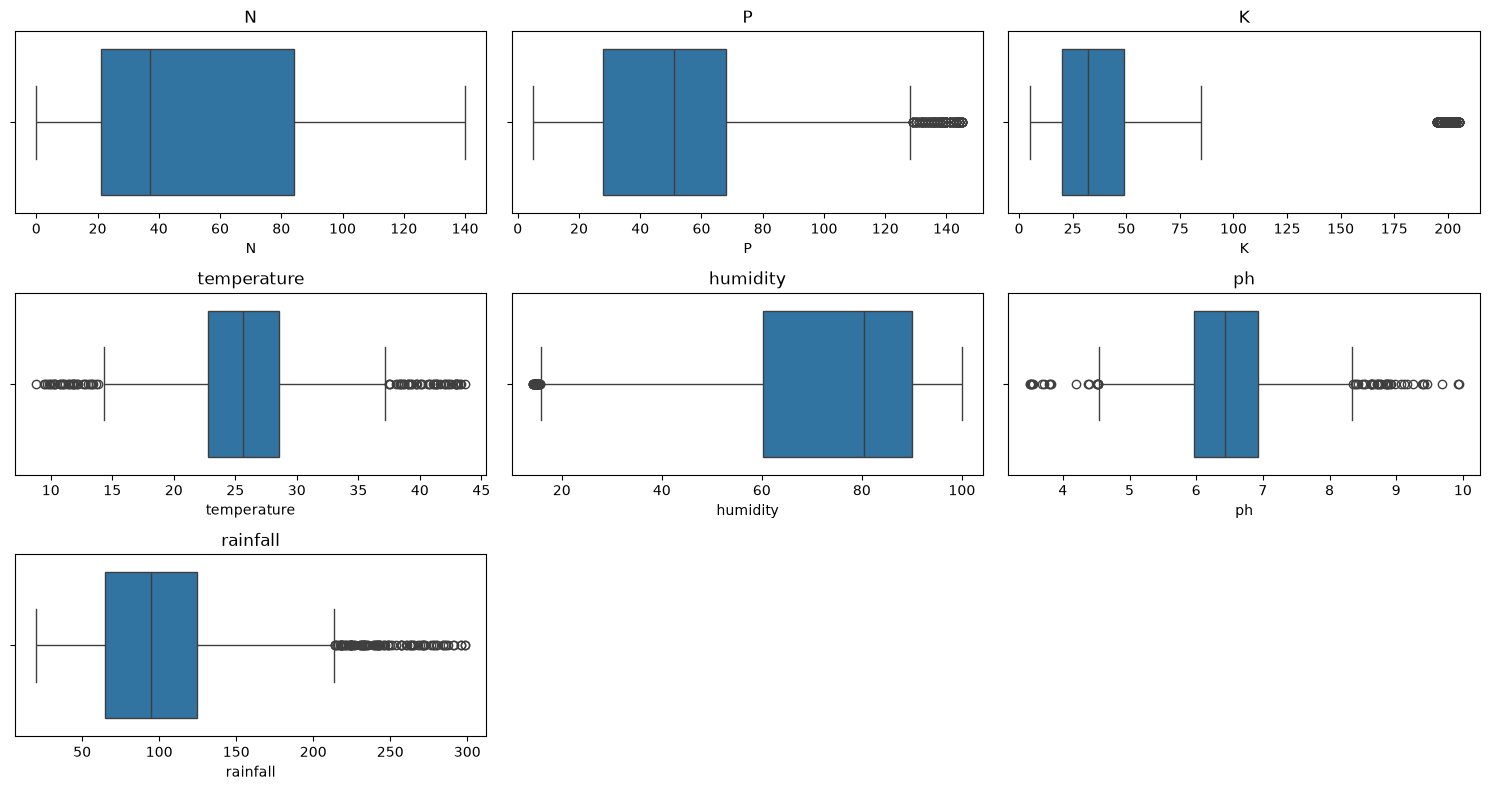

In [15]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(features, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(
        x=df[col]
    )

    plt.title(col)

plt.tight_layout()
plt.show()

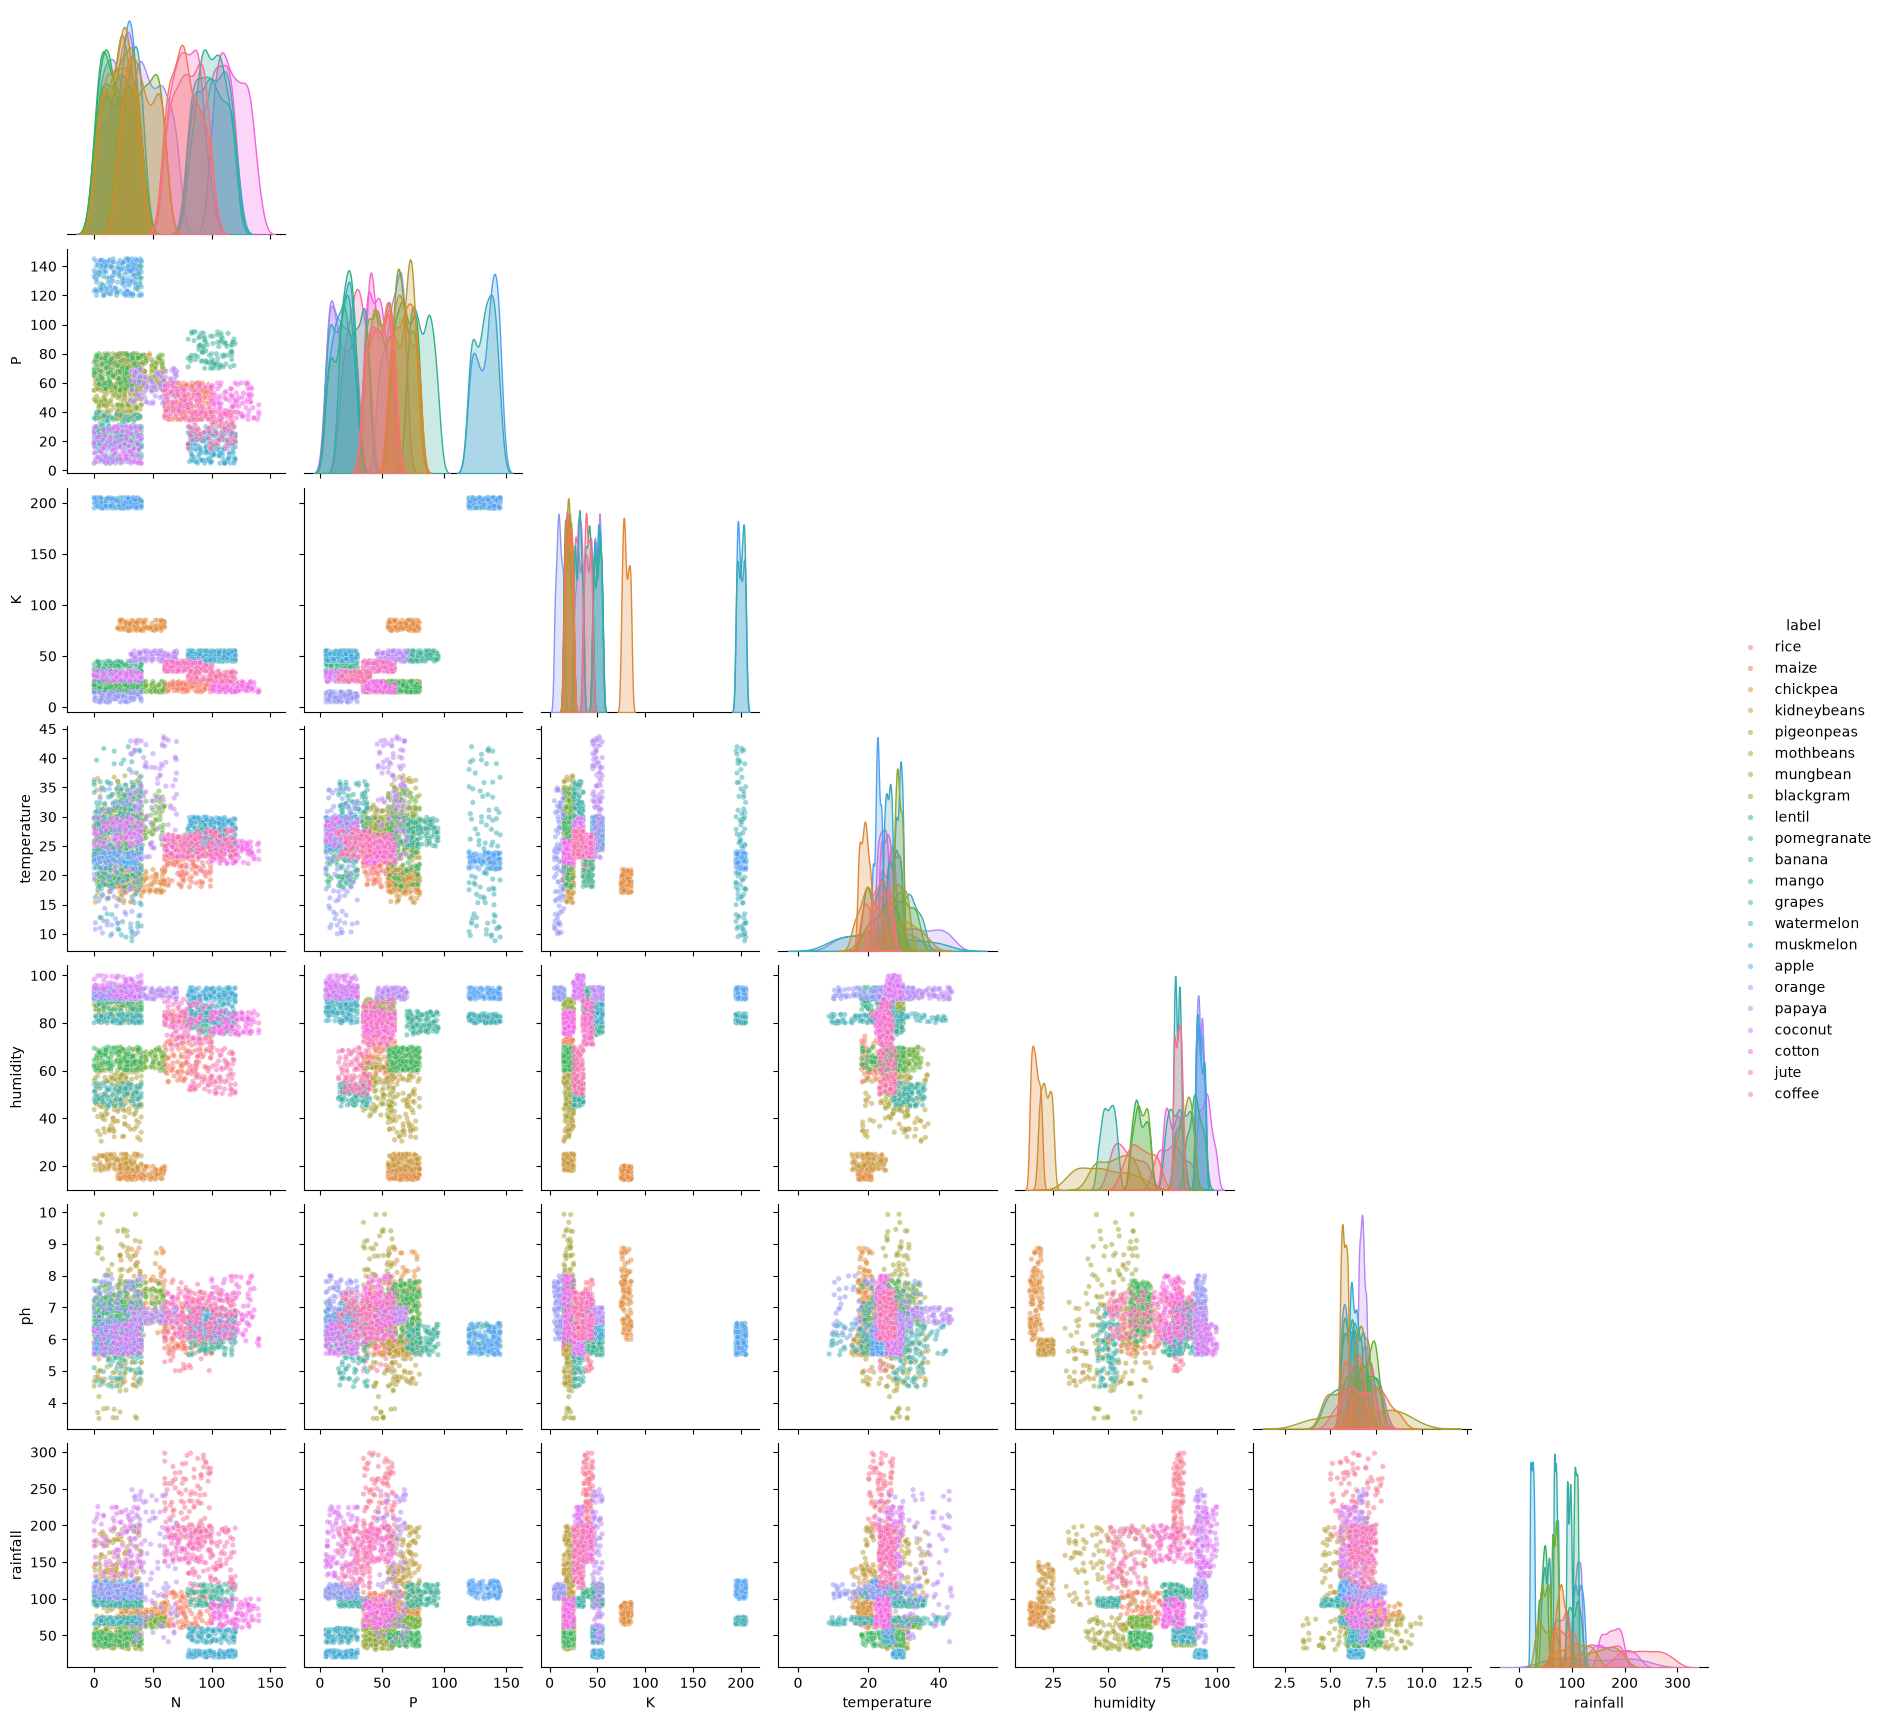

In [16]:
sns.pairplot(
    df,
    vars=features,
    hue="label",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 15}
)

plt.show()

       Feature  MI Score
4     humidity  1.729954
2            K  1.639248
6     rainfall  1.637358
1            P  1.304026
3  temperature  1.017901
0            N  1.000392
5           ph  0.686067


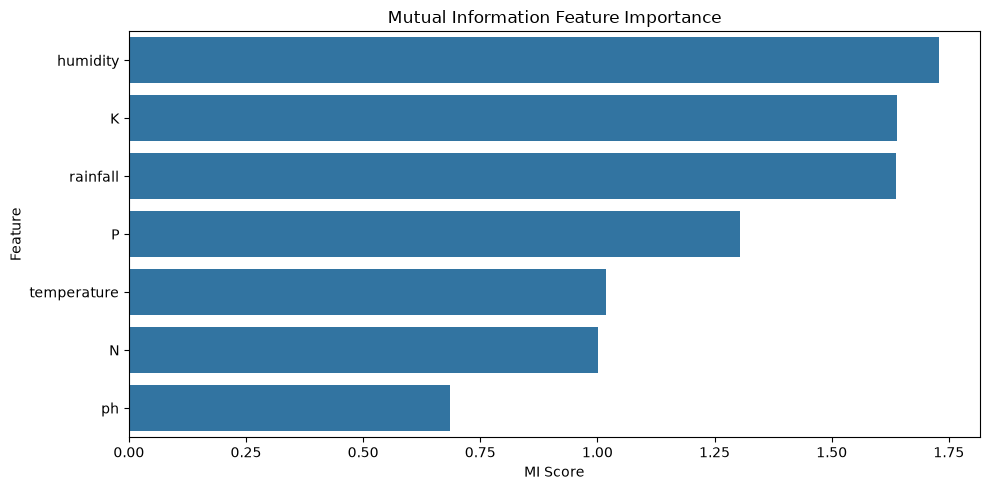

In [17]:
mi_scores = mutual_info_classif(
    X,
    y_encoded,
    random_state=SEED
)

mi_df = pd.DataFrame({
    "Feature": X.columns,
    "MI Score": mi_scores
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_df)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=mi_df,
    x="MI Score",
    y="Feature"
)

plt.title("Mutual Information Feature Importance")

plt.tight_layout()
plt.show()

In [18]:
selected_features = X.columns.tolist()

X_selected = X[selected_features].copy()

print("Selected Features:")
print(selected_features)

print("Feature Matrix Shape:",
      X_selected.shape)

Selected Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Feature Matrix Shape: (2200, 7)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_encoded,
    test_size=0.20,
    random_state=SEED,
    stratify=y_encoded
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data: (1760, 7)
Testing Data: (440, 7)

Training Labels: (1760,)
Testing Labels: (440,)


In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Scaling completed!
Training Shape: (1760, 7)
Testing Shape: (440, 7)


In [21]:
results = []

trained_models = {}

def evaluate_model(name, model, X_test_data, y_test_data):

    predictions = model.predict(X_test_data)

    accuracy = accuracy_score(
        y_test_data, predictions
    )

    precision = precision_score(
        y_test_data,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test_data,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test_data,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", "=" * 45)
    print("MODEL:", name)
    print("=" * 45)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    return predictions

In [22]:
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

lr_model.fit(
    X_train_scaled,
    y_train
)

lr_predictions = evaluate_model(
    "Logistic Regression",
    lr_model,
    X_test_scaled,
    y_test
)

trained_models["Logistic Regression"] = lr_model


MODEL: Logistic Regression
Accuracy : 0.9727
Precision: 0.974
Recall   : 0.9727
F1 Score : 0.9725


In [23]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance"
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_predictions = evaluate_model(
    "KNN",
    knn_model,
    X_test_scaled,
    y_test
)

trained_models["KNN"] = knn_model


MODEL: KNN
Accuracy : 0.9818
Precision: 0.9829
Recall   : 0.9818
F1 Score : 0.9816


In [24]:
dt_model = DecisionTreeClassifier(
    max_depth=15,
    random_state=SEED
)

dt_model.fit(
    X_train_scaled,
    y_train
)

dt_predictions = evaluate_model(
    "Decision Tree",
    dt_model,
    X_test_scaled,
    y_test
)

trained_models["Decision Tree"] = dt_model


MODEL: Decision Tree
Accuracy : 0.9818
Precision: 0.983
Recall   : 0.9818
F1 Score : 0.9817


In [25]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    X_train_scaled,
    y_train
)

rf_predictions = evaluate_model(
    "Random Forest",
    rf_model,
    X_test_scaled,
    y_test
)

trained_models["Random Forest"] = rf_model


MODEL: Random Forest
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955
F1 Score : 0.9955


In [26]:
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    random_state=SEED
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_predictions = evaluate_model(
    "SVM",
    svm_model,
    X_test_scaled,
    y_test
)

trained_models["SVM"] = svm_model


MODEL: SVM
Accuracy : 0.9886
Precision: 0.9896
Recall   : 0.9886
F1 Score : 0.9887


In [27]:
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=3,
    random_state=SEED
)

gb_model.fit(
    X_train_scaled,
    y_train
)

gb_predictions = evaluate_model(
    "Gradient Boosting",
    gb_model,
    X_test_scaled,
    y_test
)

trained_models["Gradient Boosting"] = gb_model


MODEL: Gradient Boosting
Accuracy : 0.9886
Precision: 0.9896
Recall   : 0.9886
F1 Score : 0.9887


In [28]:
et_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1
)

et_model.fit(
    X_train_scaled,
    y_train
)

et_predictions = evaluate_model(
    "Extra Trees",
    et_model,
    X_test_scaled,
    y_test
)

trained_models["Extra Trees"] = et_model


MODEL: Extra Trees
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955
F1 Score : 0.9955


In [29]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softprob",
    num_class=num_classes,
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1
)

xgb_model.fit(
    X_train_scaled,
    y_train
)

xgb_predictions = evaluate_model(
    "XGBoost",
    xgb_model,
    X_test_scaled,
    y_test
)

trained_models["XGBoost"] = xgb_model


MODEL: XGBoost
Accuracy : 0.9932
Precision: 0.9935
Recall   : 0.9932
F1 Score : 0.9931


In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

ml_cv_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "SVM": SVC(
        kernel="rbf",
        C=10
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    )
}

cv_results = []

for name, model in ml_cv_models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std()
    })

    print("Fold Scores:", scores)
    print("Mean Accuracy:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))

cv_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION RESULTS")

cv_df


Training: Logistic Regression
Fold Scores: [0.96590909 0.95738636 0.96875    0.97159091 0.97727273]
Mean Accuracy: 0.9682
Standard Deviation: 0.0066

Training: KNN
Fold Scores: [0.98295455 0.97159091 0.94602273 0.96306818 0.96306818]
Mean Accuracy: 0.9653
Standard Deviation: 0.0121

Training: Decision Tree
Fold Scores: [0.99431818 0.97727273 0.98863636 0.98863636 0.97727273]
Mean Accuracy: 0.9852
Standard Deviation: 0.0068

Training: Random Forest
Fold Scores: [1.         0.99715909 0.98863636 0.98863636 0.99431818]
Mean Accuracy: 0.9938
Standard Deviation: 0.0045

Training: SVM
Fold Scores: [0.98863636 0.98011364 0.97443182 0.98579545 0.98295455]
Mean Accuracy: 0.9824
Standard Deviation: 0.0049

Training: Extra Trees
Fold Scores: [0.99715909 0.99147727 0.98579545 0.99147727 0.99147727]
Mean Accuracy: 0.9915
Standard Deviation: 0.0036

CROSS-VALIDATION RESULTS


,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean CV Accuracy,Std CV Accuracy
0,Logistic Regression,0.965909,0.957386,0.968750,0.971591,0.977273,0.968182,0.006577
1,KNN,0.982955,0.971591,0.946023,0.963068,0.963068,0.965341,0.012106
2,Decision Tree,0.994318,0.977273,0.988636,0.988636,0.977273,0.985227,0.006818
3,Random Forest,1.000000,0.997159,0.988636,0.988636,0.994318,0.993750,0.004545
4,SVM,0.988636,0.980114,0.974432,0.985795,0.982955,0.982386,0.004888
5,Extra Trees,0.997159,0.991477,0.985795,0.991477,0.991477,0.991477,0.003593


In [32]:
X_dl_train, X_dl_val, y_dl_train, y_dl_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

dl_scaler = StandardScaler()

X_dl_train_scaled = dl_scaler.fit_transform(
    X_dl_train
)

X_dl_val_scaled = dl_scaler.transform(
    X_dl_val
)

X_dl_test_scaled = dl_scaler.transform(
    X_test
)

print("DL Training:", X_dl_train_scaled.shape)
print("DL Validation:", X_dl_val_scaled.shape)
print("DL Testing:", X_dl_test_scaled.shape)

DL Training: (1496, 7)
DL Validation: (264, 7)
DL Testing: (440, 7)


In [33]:
def create_tensor_dataset(X_data, y_data):

    X_tensor = torch.tensor(
        X_data,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y_data,
        dtype=torch.long
    )

    return TensorDataset(
        X_tensor,
        y_tensor
    )


train_dataset = create_tensor_dataset(
    X_dl_train_scaled,
    y_dl_train
)

val_dataset = create_tensor_dataset(
    X_dl_val_scaled,
    y_dl_val
)

test_dataset = create_tensor_dataset(
    X_dl_test_scaled,
    y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("PyTorch DataLoaders created!")

PyTorch DataLoaders created!


In [34]:
class ANN(nn.Module):

    def __init__(self, input_size, num_classes):

        super(ANN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        return self.network(x)


ann_model = ANN(
    input_size=X_train.shape[1],
    num_classes=num_classes
).to(device)

print(ann_model)

ANN(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=22, bias=True)
  )
)


In [35]:
class DNN(nn.Module):

    def __init__(self, input_size, num_classes):

        super(DNN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        return self.network(x)


dnn_model = DNN(
    input_size=X_train.shape[1],
    num_classes=num_classes
).to(device)

print(dnn_model)

DNN(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=256, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Linear(in_features=64, out_features=22, bias=True)
  )
)


In [36]:
class CNN1D(nn.Module):

    def __init__(self, num_classes):

        super(CNN1D, self).__init__()

        self.features = nn.Sequential(

            nn.Conv1d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64, 64),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        x = x.unsqueeze(1)

        x = self.features(x)

        return self.classifier(x)


cnn_model = CNN1D(
    num_classes=num_classes
).to(device)

print(cnn_model)

CNN1D(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=22, bias=True)
  )
)


In [37]:
def train_dl_model(
    model,
    train_loader,
    val_loader,
    epochs=100,
    patience=15,
    learning_rate=0.001
):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_val_loss = float("inf")

    best_weights = None

    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            outputs = model(xb)

            loss = criterion(outputs, yb)

            loss.backward()

            optimizer.step()

            train_loss += loss.item() * xb.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (
                predictions == yb
            ).sum().item()

            train_total += yb.size(0)

        train_loss /= train_total

        train_accuracy = train_correct / train_total

        # Validation

        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(device)
                yb = yb.to(device)

                outputs = model(xb)

                loss = criterion(outputs, yb)

                val_loss += loss.item() * xb.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == yb
                ).sum().item()

                val_total += yb.size(0)

        val_loss /= val_total

        val_accuracy = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch [{epoch+1}/{epochs}] "
                f"Train Loss: {train_loss:.4f} "
                f"Val Loss: {val_loss:.4f} "
                f"Val Accuracy: {val_accuracy:.4f}"
            )

        if patience_counter >= patience:

            print("Early stopping triggered.")

            break

    model.load_state_dict(best_weights)

    model.to(device)

    return model, history

In [38]:
ann_model, ann_history = train_dl_model(
    ann_model,
    train_loader,
    val_loader,
    epochs=100,
    patience=15
)

print("ANN Training Completed!")

Epoch [10/100] Train Loss: 0.3989 Val Loss: 0.2860 Val Accuracy: 0.9167
Epoch [20/100] Train Loss: 0.2114 Val Loss: 0.1552 Val Accuracy: 0.9432
Epoch [30/100] Train Loss: 0.1423 Val Loss: 0.1071 Val Accuracy: 0.9545
Epoch [40/100] Train Loss: 0.1153 Val Loss: 0.0971 Val Accuracy: 0.9508
Epoch [50/100] Train Loss: 0.0932 Val Loss: 0.0891 Val Accuracy: 0.9508
Epoch [60/100] Train Loss: 0.0857 Val Loss: 0.0731 Val Accuracy: 0.9697
Epoch [70/100] Train Loss: 0.0632 Val Loss: 0.0805 Val Accuracy: 0.9508
Epoch [80/100] Train Loss: 0.0584 Val Loss: 0.0644 Val Accuracy: 0.9659
Epoch [90/100] Train Loss: 0.0600 Val Loss: 0.0768 Val Accuracy: 0.9545
Epoch [100/100] Train Loss: 0.0448 Val Loss: 0.0650 Val Accuracy: 0.9621
ANN Training Completed!


In [39]:
dnn_model, dnn_history = train_dl_model(
    dnn_model,
    train_loader,
    val_loader,
    epochs=100,
    patience=15
)

print("DNN Training Completed!")

Epoch [10/100] Train Loss: 0.1004 Val Loss: 0.0993 Val Accuracy: 0.9697
Epoch [20/100] Train Loss: 0.0538 Val Loss: 0.0646 Val Accuracy: 0.9735
Epoch [30/100] Train Loss: 0.0387 Val Loss: 0.0447 Val Accuracy: 0.9773
Epoch [40/100] Train Loss: 0.0388 Val Loss: 0.0579 Val Accuracy: 0.9773
Epoch [50/100] Train Loss: 0.0460 Val Loss: 0.0402 Val Accuracy: 0.9773
Early stopping triggered.
DNN Training Completed!


In [41]:
cnn_model, cnn_history = train_dl_model(
    cnn_model,
    train_loader,
    val_loader,
    epochs=200,
    patience=15
)

print("CNN Training Completed!")

Epoch [10/200] Train Loss: 0.1315 Val Loss: 0.1737 Val Accuracy: 0.9356
Epoch [20/200] Train Loss: 0.1169 Val Loss: 0.1579 Val Accuracy: 0.9394
Epoch [30/200] Train Loss: 0.0815 Val Loss: 0.1414 Val Accuracy: 0.9470
Epoch [40/200] Train Loss: 0.0889 Val Loss: 0.1378 Val Accuracy: 0.9508
Epoch [50/200] Train Loss: 0.0708 Val Loss: 0.1184 Val Accuracy: 0.9545
Epoch [60/200] Train Loss: 0.0700 Val Loss: 0.1123 Val Accuracy: 0.9621
Epoch [70/200] Train Loss: 0.0694 Val Loss: 0.1181 Val Accuracy: 0.9583
Epoch [80/200] Train Loss: 0.0533 Val Loss: 0.1216 Val Accuracy: 0.9545
Epoch [90/200] Train Loss: 0.0488 Val Loss: 0.1135 Val Accuracy: 0.9545
Epoch [100/200] Train Loss: 0.0402 Val Loss: 0.1004 Val Accuracy: 0.9583
Epoch [110/200] Train Loss: 0.0465 Val Loss: 0.1269 Val Accuracy: 0.9470
Early stopping triggered.
CNN Training Completed!


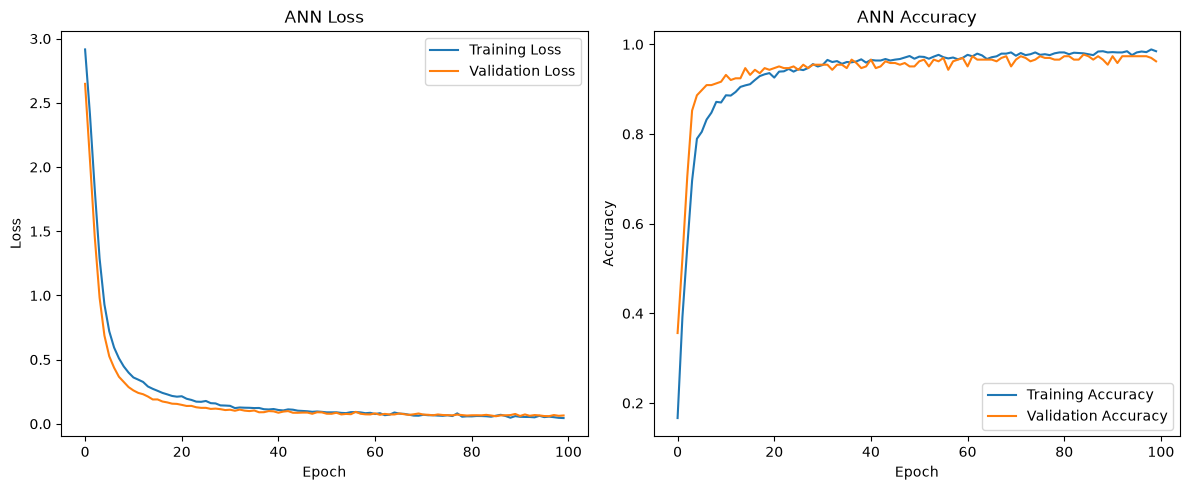

In [42]:
def plot_training_history(history, model_name):

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.plot(
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.title(model_name + " Loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(
        history["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(model_name + " Accuracy")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()

    plt.tight_layout()

    plt.show()


plot_training_history(ann_history, "ANN")

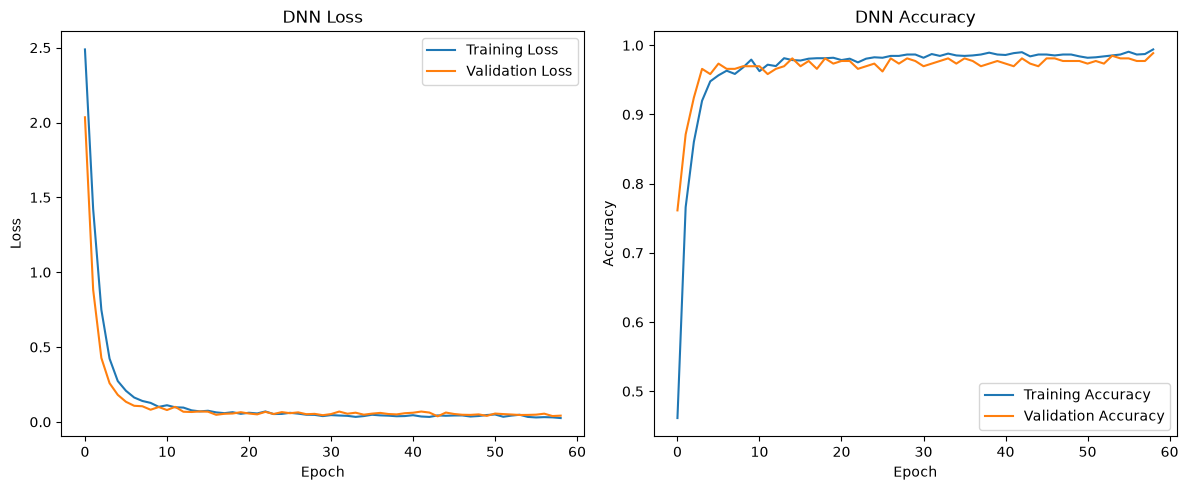

In [43]:
plot_training_history(
    dnn_history,
    "DNN"
)

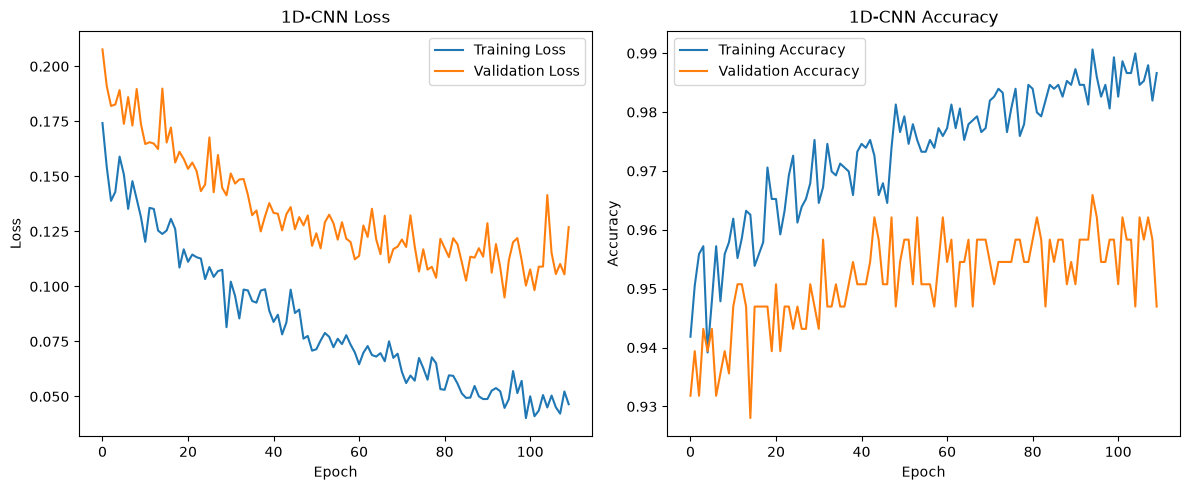

In [44]:
plot_training_history(
    cnn_history,
    "1D-CNN"
)

In [45]:
def predict_dl_model(model, data_loader):

    model.eval()

    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for xb, yb in data_loader:

            xb = xb.to(device)

            outputs = model(xb)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_predictions),
        np.array(all_probabilities)
    )


ann_predictions, ann_probabilities = predict_dl_model(
    ann_model,
    test_loader
)

dnn_predictions, dnn_probabilities = predict_dl_model(
    dnn_model,
    test_loader
)

cnn_predictions, cnn_probabilities = predict_dl_model(
    cnn_model,
    test_loader
)

print("DL predictions generated successfully!")

DL predictions generated successfully!


In [46]:
def evaluate_dl_model(name, predictions):

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\nModel:", name)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))


evaluate_dl_model("ANN", ann_predictions)

evaluate_dl_model("DNN", dnn_predictions)

evaluate_dl_model("1D-CNN", cnn_predictions)


Model: ANN
Accuracy : 0.9886
Precision: 0.9903
Recall   : 0.9886
F1 Score : 0.9885

Model: DNN
Accuracy : 0.9932
Precision: 0.9937
Recall   : 0.9932
F1 Score : 0.9932

Model: 1D-CNN
Accuracy : 0.9886
Precision: 0.9892
Recall   : 0.9886
F1 Score : 0.9887


In [47]:
xgb_probabilities = xgb_model.predict_proba(
    X_test_scaled
)

print("XGBoost Probability Shape:",
      xgb_probabilities.shape)

print("ANN Probability Shape:",
      ann_probabilities.shape)

XGBoost Probability Shape: (440, 22)
ANN Probability Shape: (440, 22)


In [48]:
alpha = 0.5

hybrid_probabilities = (
    alpha * xgb_probabilities +
    (1 - alpha) * ann_probabilities
)

hybrid_predictions = np.argmax(
    hybrid_probabilities,
    axis=1
)

evaluate_dl_model(
    "Hybrid XGBoost + ANN",
    hybrid_predictions
)

print("\nHybrid model completed!")


Model: Hybrid XGBoost + ANN
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955
F1 Score : 0.9955

Hybrid model completed!


In [49]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")

results_df

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.995455,0.995671,0.995455,0.995452
1,Extra Trees,0.995455,0.995671,0.995455,0.995452
2,Hybrid XGBoost + ANN,0.995455,0.995671,0.995455,0.995452
3,DNN,0.993182,0.993703,0.993182,0.993169
4,XGBoost,0.993182,0.993506,0.993182,0.993116
5,SVM,0.988636,0.989571,0.988636,0.988674
6,ANN,0.988636,0.990260,0.988636,0.988543
7,Gradient Boosting,0.988636,0.989571,0.988636,0.988674
8,1D-CNN,0.988636,0.989245,0.988636,0.988735
9,KNN,0.981818,0.982881,0.981818,0.981609


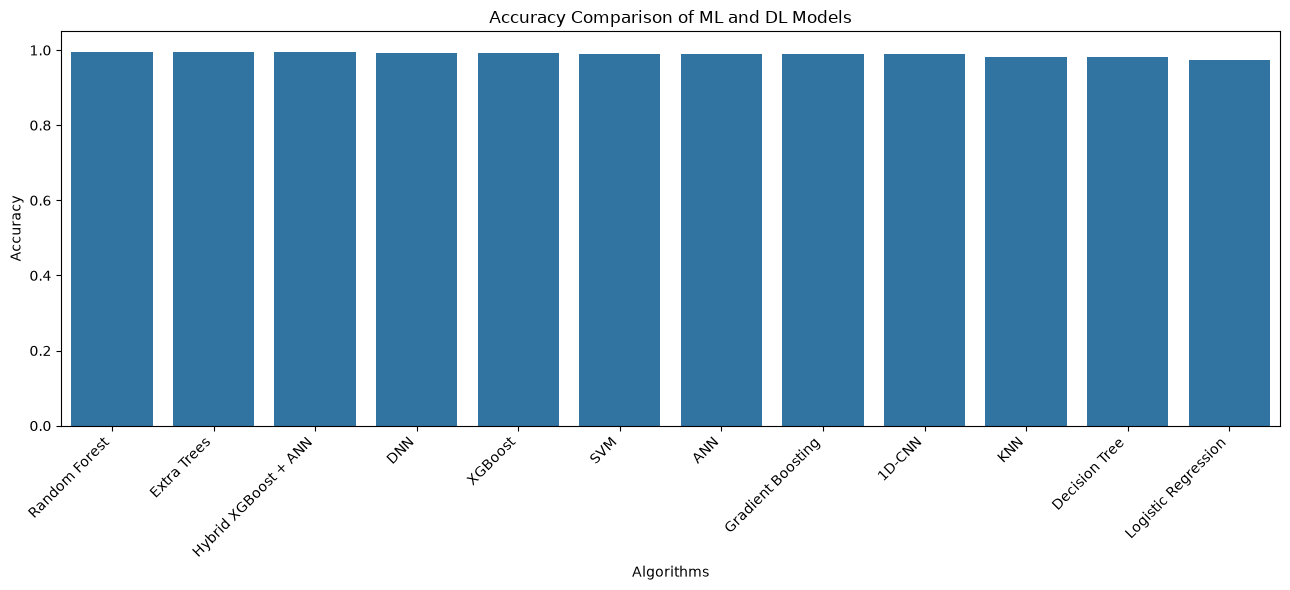

In [50]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of ML and DL Models")

plt.xlabel("Algorithms")
plt.ylabel("Accuracy")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1.05)

plt.tight_layout()

plt.show()

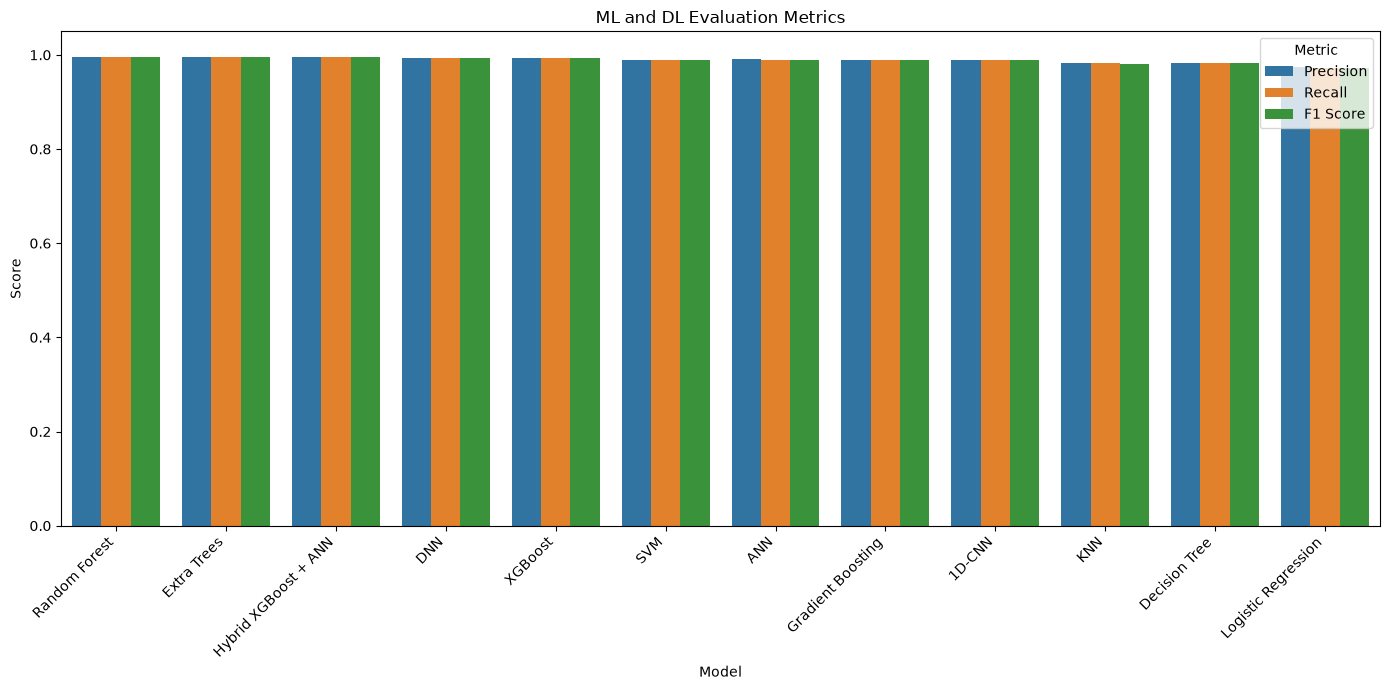

In [51]:
comparison_metrics = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_metrics,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("ML and DL Evaluation Metrics")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1.05)

plt.tight_layout()

plt.show()

In [52]:
best_model_name = results_df.iloc[0]["Model"]

best_accuracy = results_df.iloc[0]["Accuracy"]

print("Best Model:", best_model_name)

print("Best Accuracy:", round(best_accuracy, 4))

print(
    "Best Accuracy Percentage:",
    round(best_accuracy * 100, 2),
    "%"
)

Best Model: Random Forest
Best Accuracy: 0.9955
Best Accuracy Percentage: 99.55 %


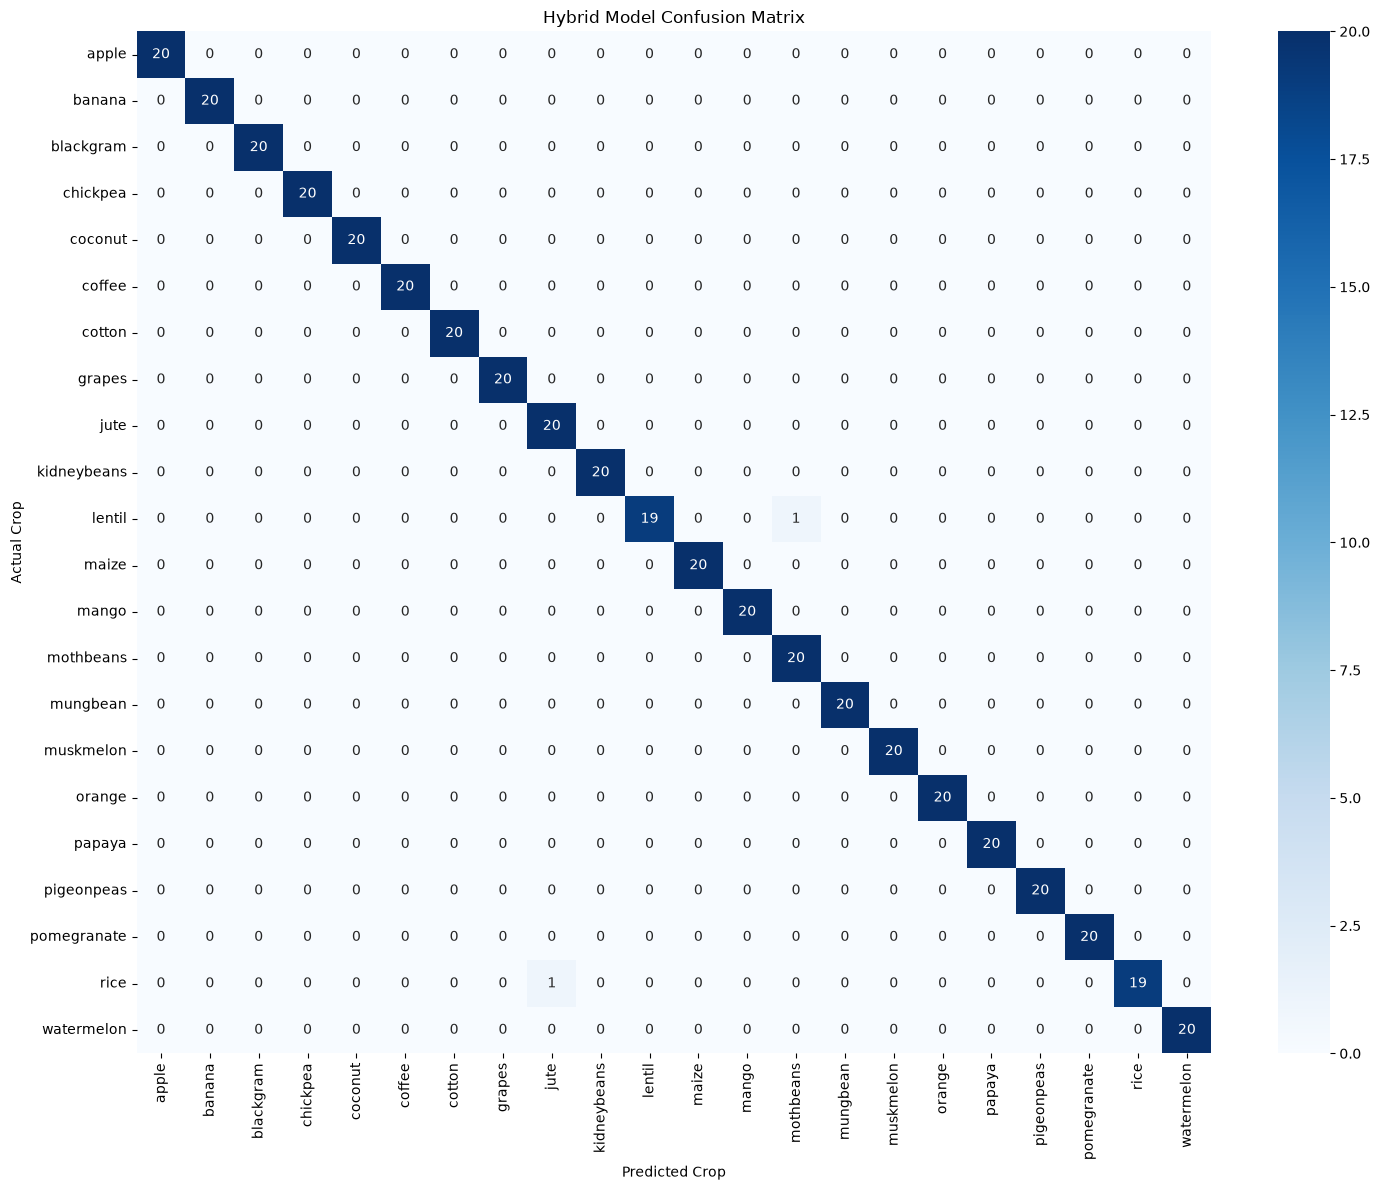

In [53]:
cm = confusion_matrix(
    y_test,
    hybrid_predictions
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Hybrid Model Confusion Matrix")

plt.xlabel("Predicted Crop")

plt.ylabel("Actual Crop")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [54]:
print(
    classification_report(
        y_test,
        hybrid_predictions,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

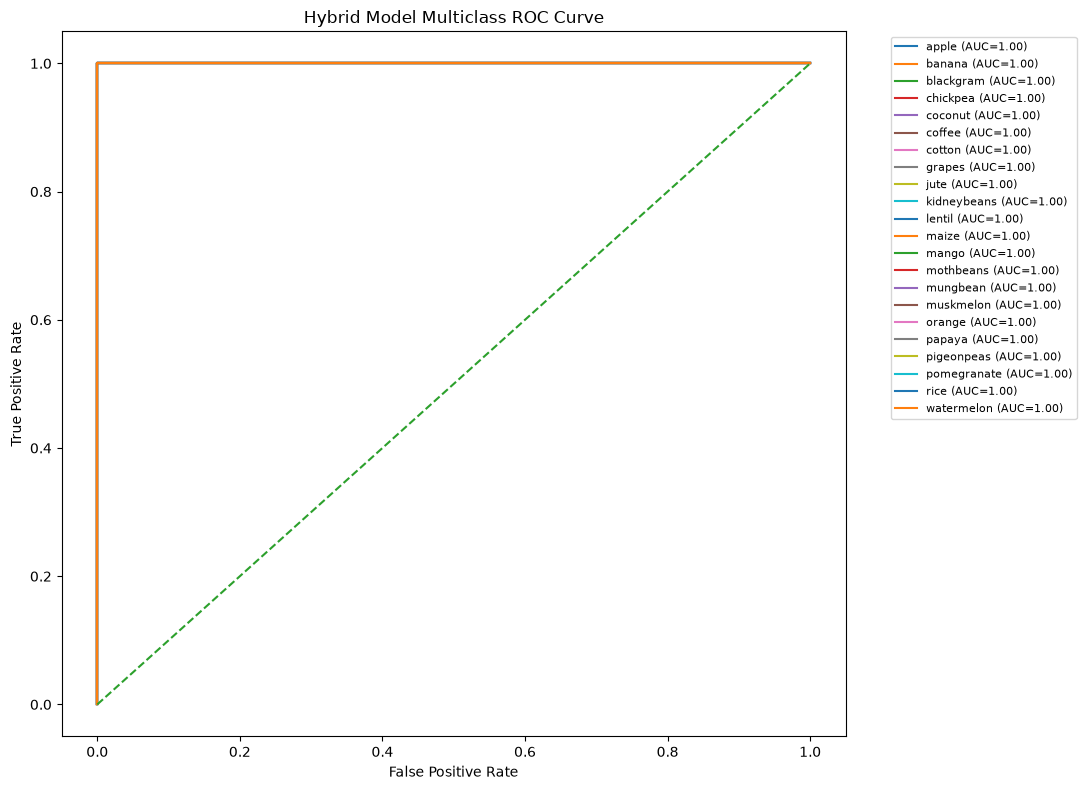

In [55]:
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

plt.figure(figsize=(11, 8))

for i in range(num_classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        hybrid_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[i]} (AUC={roc_auc:.2f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Hybrid Model Multiclass ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.show()

In [56]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(
    y_test,
    hybrid_probabilities,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_test,
    hybrid_probabilities,
    multi_class="ovr",
    average="weighted"
)

print("Macro ROC-AUC:", round(macro_auc, 4))

print("Weighted ROC-AUC:", round(weighted_auc, 4))

Macro ROC-AUC: 1.0
Weighted ROC-AUC: 1.0


       Feature  Importance
2            K    0.194658
6     rainfall    0.178967
4     humidity    0.175952
1            P    0.165721
0            N    0.152980
3  temperature    0.076883
5           ph    0.054840


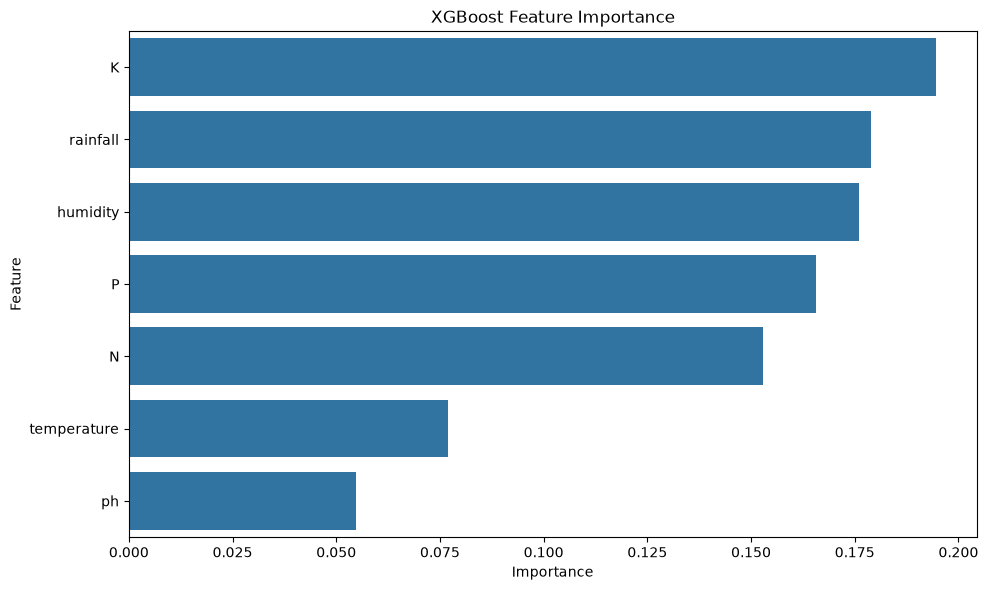

In [57]:
importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("XGBoost Feature Importance")

plt.tight_layout()

plt.show()


SHAP output type: <class 'numpy.ndarray'>

SHAP FEATURE IMPORTANCE


,Feature,Mean Absolute SHAP
4,humidity,0.999668
6,rainfall,0.934134
1,P,0.740052
2,K,0.523701
0,N,0.514285
3,temperature,0.224507
5,ph,0.141456


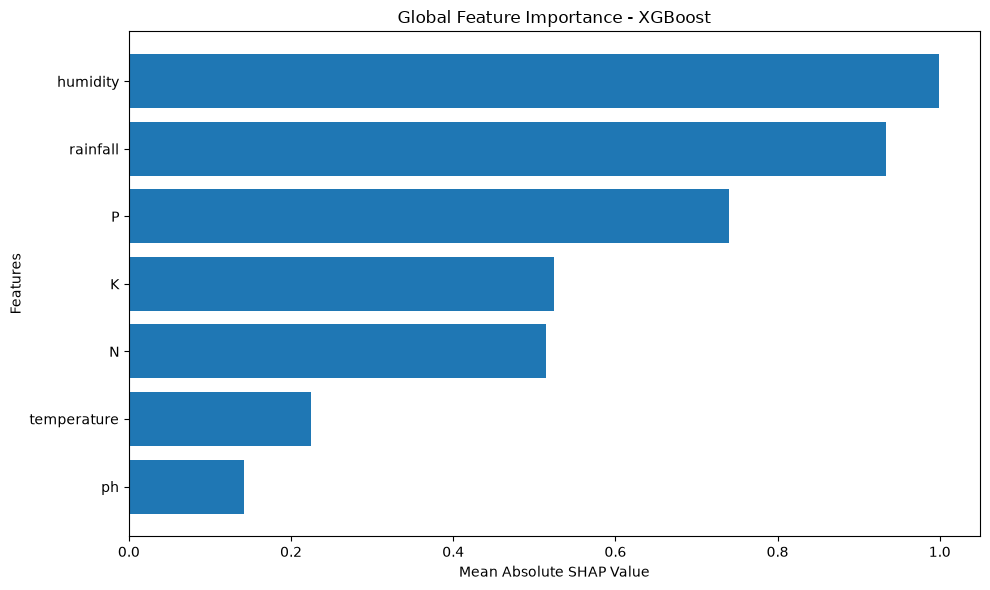

In [59]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# Select 100 test samples
X_shap = X_test_scaled[:100]

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP output type:", type(shap_values))

# Handle multiclass SHAP output
if isinstance(shap_values, list):

    # Older SHAP versions return a list (one array per class)
    shap_array = np.stack(shap_values, axis=0)

    # Average absolute SHAP values across classes
    mean_shap = np.mean(np.abs(shap_array), axis=0)

elif isinstance(shap_values, np.ndarray):

    if shap_values.ndim == 3:
        # Shape: samples × features × classes
        mean_shap = np.mean(np.abs(shap_values), axis=2)

    elif shap_values.ndim == 2:
        # Shape: samples × features
        mean_shap = np.abs(shap_values)

    else:
        raise ValueError(
            f"Unexpected SHAP array shape: {shap_values.shape}"
        )

else:
    raise TypeError("Unsupported SHAP output format")

# Plot global feature importance
feature_importance = np.mean(mean_shap, axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Mean Absolute SHAP": feature_importance
}).sort_values(
    by="Mean Absolute SHAP",
    ascending=False
)

print("\nSHAP FEATURE IMPORTANCE")
display(shap_importance_df)

# Plot bar graph
plt.figure(figsize=(10, 6))
plt.barh(
    shap_importance_df["Feature"],
    shap_importance_df["Mean Absolute SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Global Feature Importance - XGBoost")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [60]:
os.makedirs("models", exist_ok=True)

print("Models directory created!")

Models directory created!


In [61]:
for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".pkl"
    )

    joblib.dump(
        model,
        os.path.join("models", filename)
    )

print("All ML models saved!")

All ML models saved!


In [62]:
joblib.dump(
    scaler,
    "models/ml_scaler.pkl"
)

joblib.dump(
    dl_scaler,
    "models/dl_scaler.pkl"
)

joblib.dump(
    label_encoder,
    "models/label_encoder.pkl"
)

joblib.dump(
    selected_features,
    "models/selected_features.pkl"
)

print("Preprocessing objects saved!")

Preprocessing objects saved!


In [63]:
torch.save(
    {
        "model_state_dict": ann_model.state_dict(),
        "input_size": X_train.shape[1],
        "num_classes": num_classes,
        "class_names": class_names.tolist()
    },
    "models/ann_model.pt"
)

torch.save(
    {
        "model_state_dict": dnn_model.state_dict(),
        "input_size": X_train.shape[1],
        "num_classes": num_classes,
        "class_names": class_names.tolist()
    },
    "models/dnn_model.pt"
)

torch.save(
    {
        "model_state_dict": cnn_model.state_dict(),
        "input_size": X_train.shape[1],
        "num_classes": num_classes,
        "class_names": class_names.tolist()
    },
    "models/cnn_model.pt"
)

print("DL models saved successfully!")

DL models saved successfully!


In [64]:
def recommend_crop(
    nitrogen,
    phosphorus,
    potassium,
    temperature,
    humidity,
    ph,
    rainfall
):

    input_data = pd.DataFrame(
        [[
            nitrogen,
            phosphorus,
            potassium,
            temperature,
            humidity,
            ph,
            rainfall
        ]],
        columns=selected_features
    )

    # ML prediction

    input_ml = scaler.transform(input_data)

    xgb_probs = xgb_model.predict_proba(
        input_ml
    )

    # DL prediction

    input_dl = dl_scaler.transform(input_data)

    input_tensor = torch.tensor(
        input_dl,
        dtype=torch.float32
    ).to(device)

    ann_model.eval()

    with torch.no_grad():

        ann_output = ann_model(input_tensor)

        ann_probs = torch.softmax(
            ann_output,
            dim=1
        ).cpu().numpy()

    # Hybrid prediction

    final_probs = (
        alpha * xgb_probs +
        (1 - alpha) * ann_probs
    )

    top_indices = np.argsort(
        final_probs[0]
    )[::-1][:3]

    print("\nINTELLIGENT CROP RECOMMENDATION")
    print("=" * 45)

    for rank, index in enumerate(top_indices, 1):

        crop = label_encoder.inverse_transform(
            [index]
        )[0]

        confidence = final_probs[0][index] * 100

        print(
            f"{rank}. {crop.title()} "
            f"- {confidence:.2f}% model score"
        )

    return final_probs

In [65]:
recommend_crop(
    nitrogen=90,
    phosphorus=42,
    potassium=43,
    temperature=20.87,
    humidity=82.00,
    ph=6.50,
    rainfall=202.93
)


INTELLIGENT CROP RECOMMENDATION
1. Rice - 92.71% model score
2. Jute - 7.19% model score
3. Coffee - 0.01% model score


array([[4.8987309e-05, 9.0278583e-05, 3.0091553e-05, 5.5301447e-05,
        6.6610533e-05, 1.2369113e-04, 4.1166924e-05, 5.1083483e-05,
        7.1870558e-02, 3.2397147e-05, 2.8080527e-05, 5.3908159e-05,
        3.7377435e-05, 2.7682036e-05, 3.7817808e-05, 5.9374182e-05,
        5.1892130e-05, 3.9300983e-05, 5.7672372e-05, 6.6348184e-05,
        9.2707074e-01, 5.9611612e-05]], dtype=float32)

In [66]:
print("=" * 60)

print("INTELLIGENT CROP RECOMMENDATION RESEARCH SUMMARY")

print("=" * 60)

print("Dataset Records:", len(df))

print("Number of Features:", X.shape[1])

print("Number of Crop Classes:", num_classes)

print("Number of ML/DL/Hybrid Experiments:", len(results_df))

print("\nBest Performing Model:", best_model_name)

print(
    "Best Test Accuracy:",
    round(best_accuracy * 100, 2),
    "%"
)

print("\nHybrid Model ROC-AUC:", round(macro_auc, 4))

print("\nAll experiments completed!")

INTELLIGENT CROP RECOMMENDATION RESEARCH SUMMARY
Dataset Records: 2200
Number of Features: 7
Number of Crop Classes: 22
Number of ML/DL/Hybrid Experiments: 12

Best Performing Model: Random Forest
Best Test Accuracy: 99.55 %

Hybrid Model ROC-AUC: 1.0

All experiments completed!
